<a href="https://colab.research.google.com/github/prattayabsmrstu/GioAI_Gopalganj-flood/blob/python-code/validation_notebook_optimized.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files
print("Ctrl+A দিয়ে সব ফাইল একসাথে সিলেক্ট করুন:")
uploaded = files.upload()
print(f"\n✅ {len(uploaded)} ফাইল আপলোড হয়েছে")
for f in sorted(uploaded): print("  -", f)

Ctrl+A দিয়ে সব ফাইল একসাথে সিলেক্ট করুন:


Saving Gopalganj_Boundary.kml to Gopalganj_Boundary.kml
Saving Gopalganj_DFO_Events.geojson to Gopalganj_DFO_Events.geojson
Saving Gopalganj_DFO_overlap_approx.csv to Gopalganj_DFO_overlap_approx.csv
Saving Gopalganj_DryMAD_VH.tif to Gopalganj_DryMAD_VH.tif
Saving Gopalganj_DryMedian_VH.tif to Gopalganj_DryMedian_VH.tif
Saving Gopalganj_FloodFreq_2019.tif to Gopalganj_FloodFreq_2019.tif
Saving Gopalganj_FloodFreq_2019_2024.tif to Gopalganj_FloodFreq_2019_2024.tif
Saving Gopalganj_FloodFreq_2020.tif to Gopalganj_FloodFreq_2020.tif
Saving Gopalganj_FloodFreq_2021.tif to Gopalganj_FloodFreq_2021.tif
Saving Gopalganj_FloodFreq_2022.tif to Gopalganj_FloodFreq_2022.tif
Saving Gopalganj_FloodFreq_2023.tif to Gopalganj_FloodFreq_2023.tif
Saving Gopalganj_FloodFreq_2024.tif to Gopalganj_FloodFreq_2024.tif
Saving Gopalganj_FloodFrequency_GEE.js to Gopalganj_FloodFrequency_GEE.js
Saving Gopalganj_ML_Samples_SpatialBlock_5km.csv to Gopalganj_ML_Samples_SpatialBlock_5km.csv
Saving Gopalganj_ML_Samp

মূল: Gopalganj_FloodFreq_2019_2024.tif
সীমানা: Gopalganj_Boundary.kml
DFO: Gopalganj_DFO_Events.geojson
পিক্সেল এরিয়া = 0.0003665 km²
সীমানা লোড ✓ — জেলার ভেতরের পিক্সেল: 7,082,048
জেলার আয়তন (ভ্যালিড) : 2,595.5 km²
>10% ফ্লাড এলাকা      : 214.0 km² (8.24%)
>50% ফ্লাড এলাকা      : 0.2 km² (0.01%)
গড় / মিডিয়ান / P95   : 3.09% / 1.18% / 12.43%
সর্বোচ্চ              : 67.46%


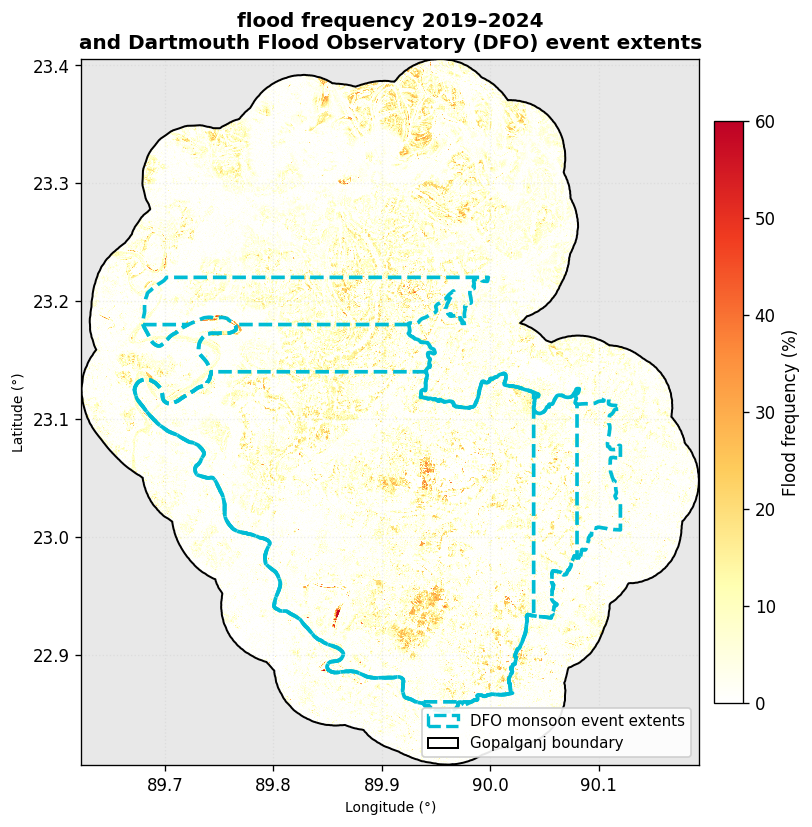

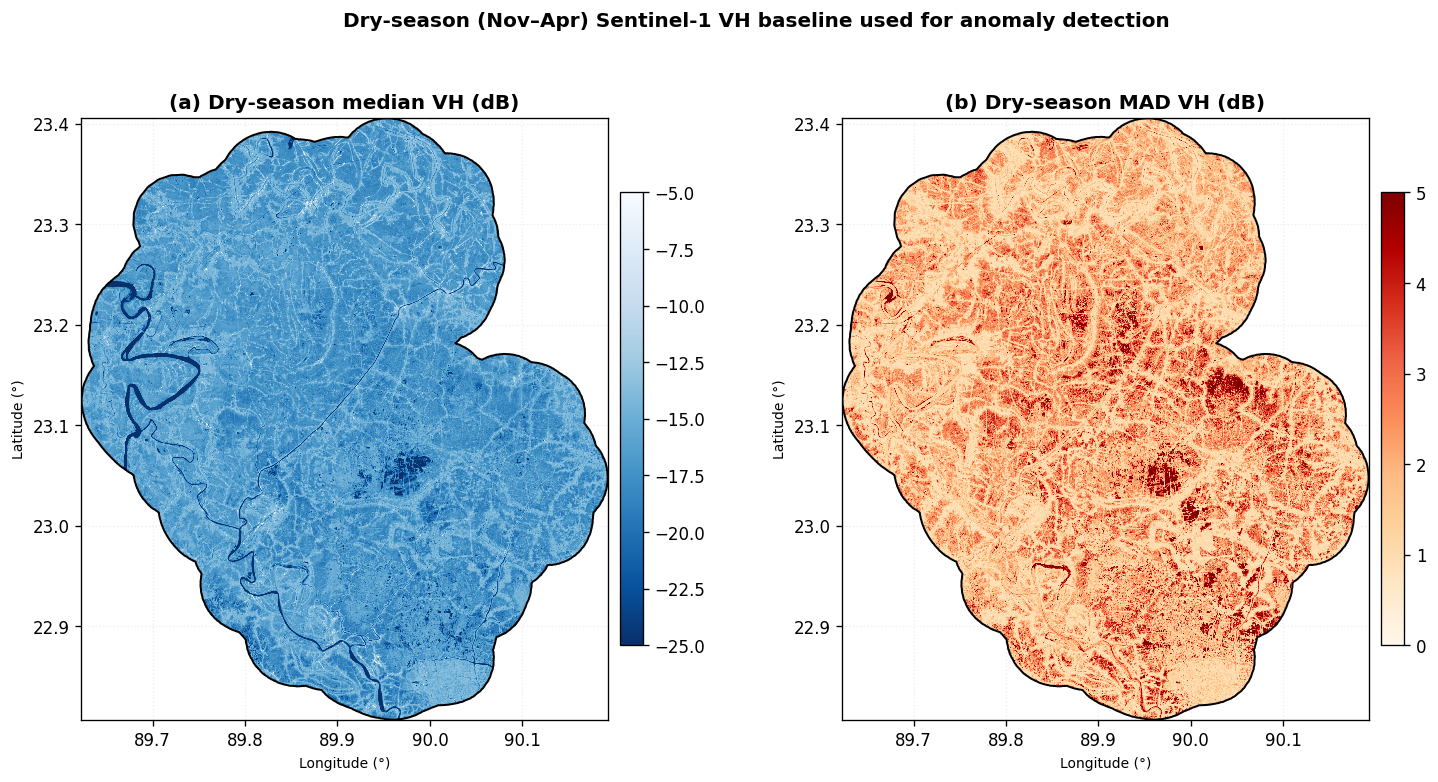

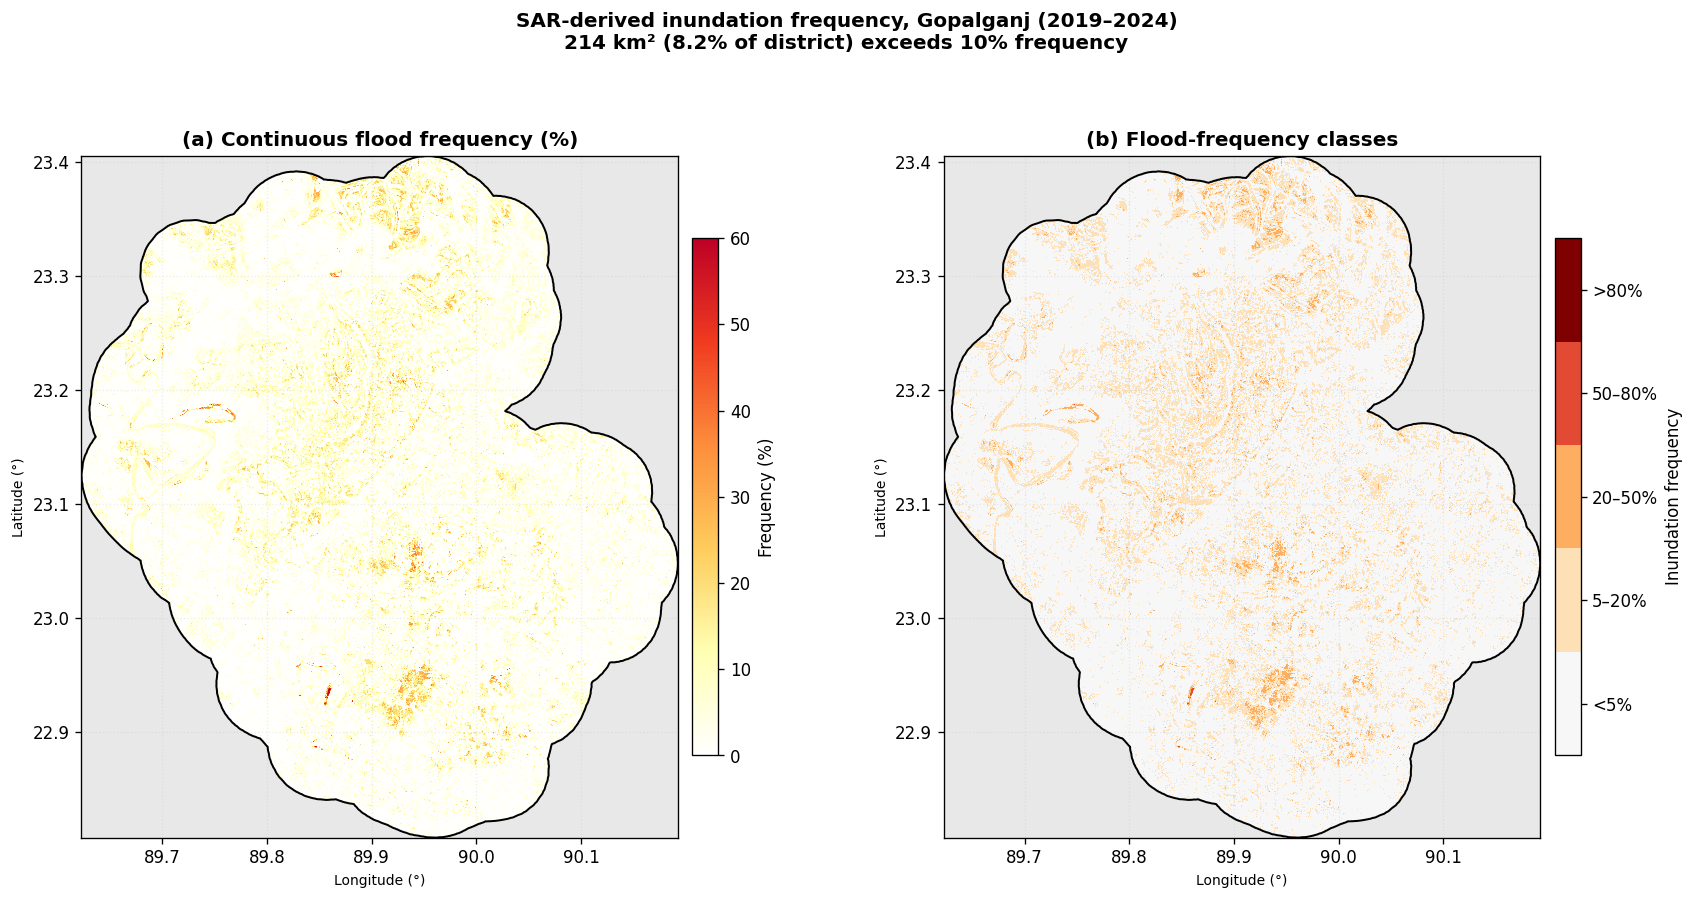

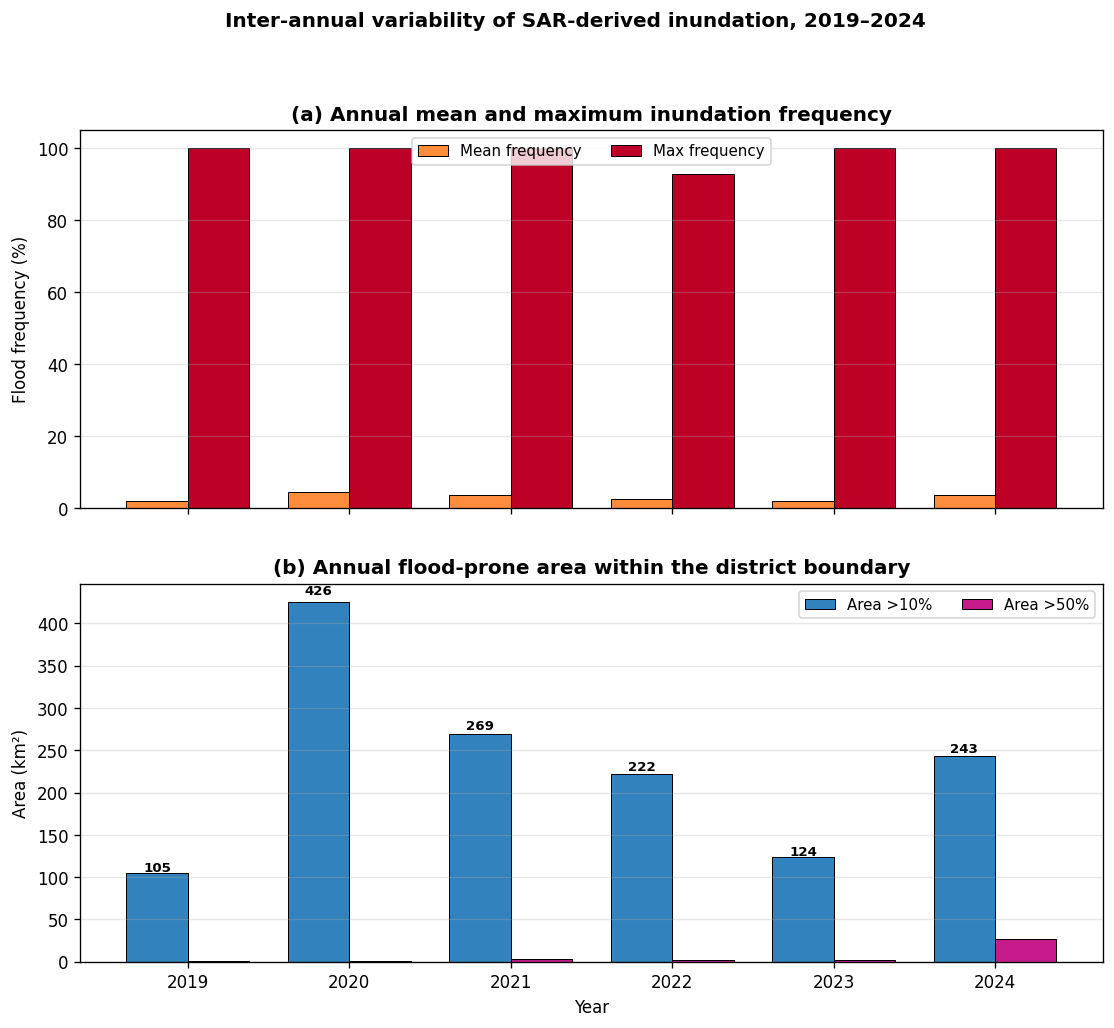

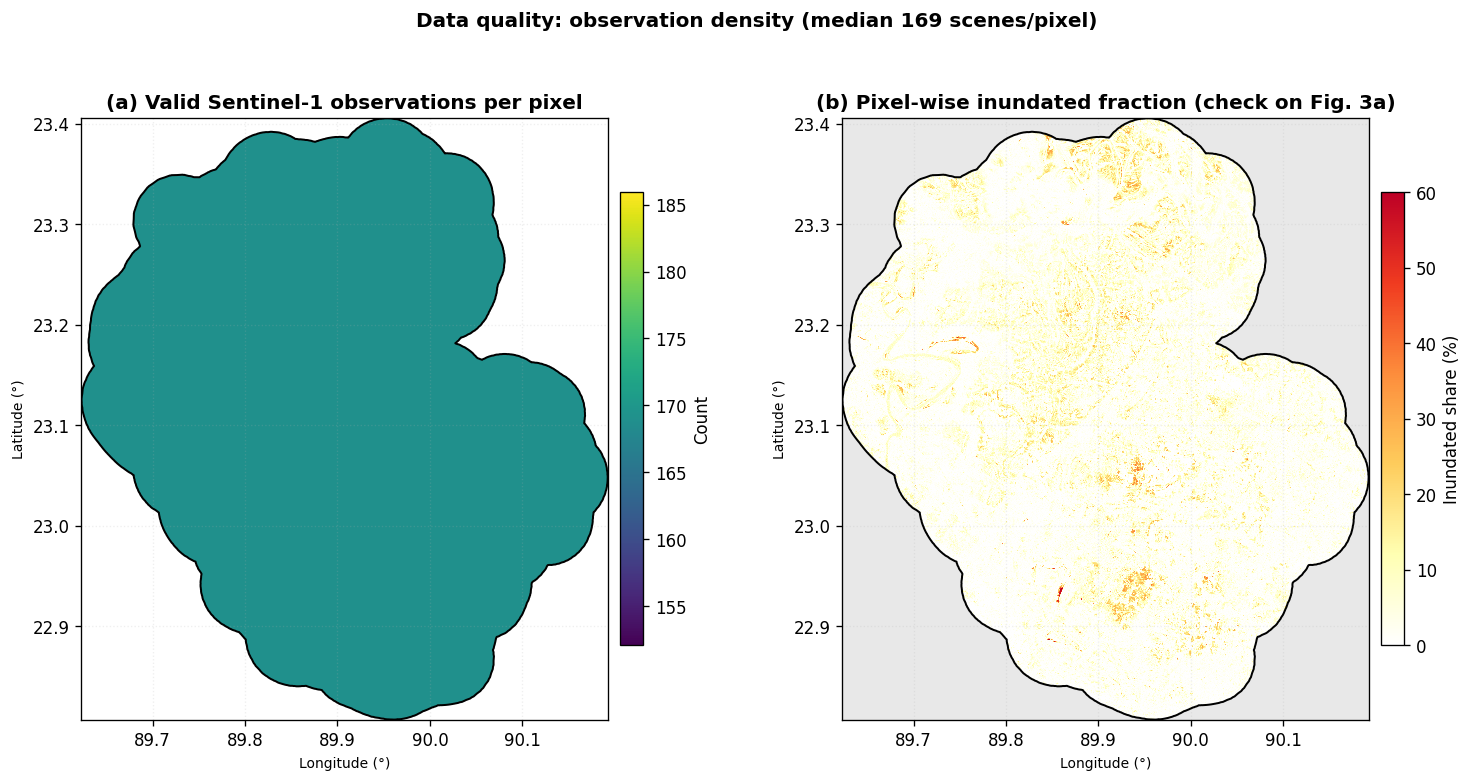

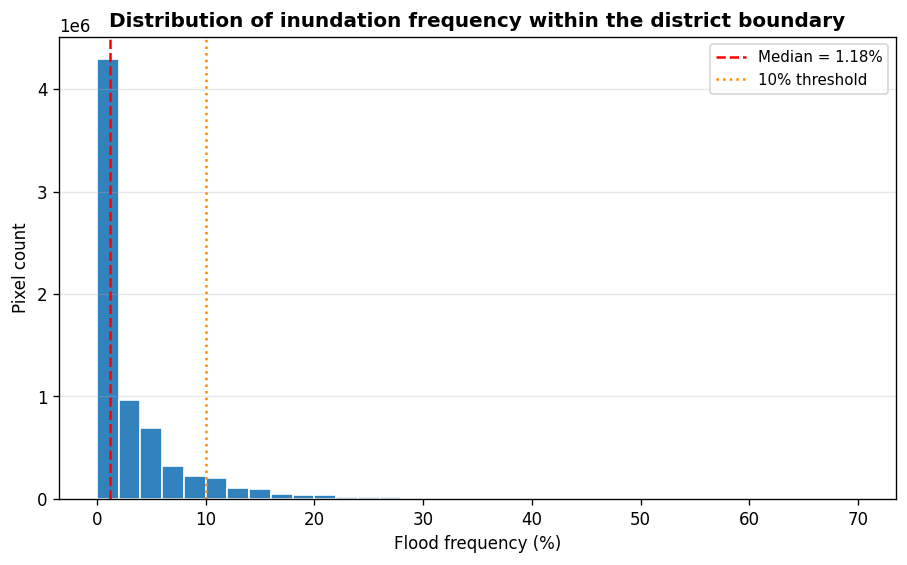


--- টেবিল: ফ্লাড ফ্রিকোয়েন্সি ক্লাস অনুযায়ী এলাকা ---
 Class  Pixels  Area_km2  Share_pct
   <5% 5662758    2075.3      79.89
 5–20% 1334235     489.0      18.82
20–50%   90801      33.3       1.28
50–80%     614       0.2       0.01
  >80%       0       0.0       0.00

--- সারাংশ ---
 district_area_km2  area_gt10_km2  area_gt50_km2  mean_pct  median_pct  p95_pct  max_pct  pixel_area_km2
            2595.5          214.0            0.2      3.09        1.18    12.43    67.46        0.000366

✅ প্যাকেজ তৈরি: Gopalganj_publication_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
!pip install -q rasterio geopandas matplotlib seaborn pandas numpy openpyxl

import math, io, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
import rasterio
from rasterio.features import geometry_mask, rasterize
import geopandas as gpd
import warnings; warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10, "legend.fontsize": 9,
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.facecolor": "white",
})

names = list(uploaded.keys())
def pick(*keys, ext=None):
    for k in keys:
        for n in names:
            if k.lower() in n.lower() and (ext is None or n.lower().endswith(ext)):
                return n
    return None

F_MAIN   = pick("FloodFreq_2019_2024", ext=(".tif",))
F_ANNUAL = {y: pick(f"FloodFreq_{y}", ext=(".tif",)) for y in range(2019, 2025)}
F_WCOUNT = pick("WaterCount", ext=(".tif",))
F_TOBS   = pick("TotalObs", ext=(".tif",))
F_DRYMAD = pick("DryMAD", ext=(".tif",))
F_DRYMED = pick("DryMedian", ext=(".tif",))
F_DFO    = pick("DFO_Events", ext=(".geojson", ".json", ".shp"))
F_BOUND  = pick("Boundary", ext=(".kml", ".geojson", ".shp", ".json"))
F_OVER   = pick("DFO_overlap", ext=(".xlsx", ".csv"))

print("মূল:", F_MAIN); print("সীমানা:", F_BOUND); print("DFO:", F_DFO)

def load(p):
    with rasterio.open(p) as s:
        a = s.read(1).astype("float64")
        if s.nodata is not None: a[a == s.nodata] = np.nan
        return dict(arr=a, transform=s.transform, crs=s.crs, res=s.res, prof=s.profile)

main = load(F_MAIN)
crs, tf, res, shape = main["crs"], main["transform"], main["res"], main["shape"] if "shape" in main else main["arr"].shape

def px_area_km2(res, crs, lat=23.0):
    if "4326" in str(crs).upper():
        phi = math.radians(lat)
        m_lat = 111132.92 - 559.82*math.cos(2*phi) + 1.175*math.cos(4*phi)
        m_lon = 111412.84*math.cos(phi) - 93.5*math.cos(3*phi) + 0.118*math.cos(5*phi)
        return (abs(res[0])*m_lon * abs(res[1])*m_lat) / 1e6
    return (abs(res[0])*abs(res[1]))/1e6

PA = px_area_km2(res, crs)
print(f"পিক্সেল এরিয়া = {PA:.7f} km²")

# ---- জেলা-সীমানা মাস্ক ----
district = None
if F_BOUND:
    try:
        district = gpd.read_file(F_BOUND)
        if district.crs is None: district = district.set_crs("EPSG:4326")
        district = district.to_crs(crs)
        dmask = ~geometry_mask(district.geometry, out_shape=shape, transform=tf, invert=False)
        print("সীমানা লোড ✓ — জেলার ভেতরের পিক্সেল:", f"{dmask.sum():,}")
    except Exception as e:
        print("সীমানা পড়া যায়নি:", e); dmask = np.ones(shape, bool)
else:
    dmask = np.ones(shape, bool); print("সীমানা নেই — বাফারসহ হিসাব হবে")

def clip_stats(a, extra_mask=None):
    m = ~np.isnan(a)
    if extra_mask is not None: m &= extra_mask
    v = a[m]
    return v, m

def extent(a, t):
    return (t.c, t.c + a.shape[1]*t.a, t.f + a.shape[0]*t.e, t.f)

ext = extent(main["arr"], tf)
flood = main["arr"].copy()
flood[(flood < 0) | (flood > 100)] = np.nan
v, vmask = clip_stats(flood, dmask)

dist_area = vmask.sum() * PA
A10 = (v > 10).sum() * PA
A50 = (v > 50).sum() * PA

print("="*55)
print(f"জেলার আয়তন (ভ্যালিড) : {dist_area:,.1f} km²")
print(f">10% ফ্লাড এলাকা      : {A10:,.1f} km² ({100*A10/dist_area:.2f}%)")
print(f">50% ফ্লাড এলাকা      : {A50:,.1f} km² ({100*A50/dist_area:.2f}%)")
print(f"গড় / মিডিয়ান / P95   : {np.mean(v):.2f}% / {np.median(v):.2f}% / {np.percentile(v,95):.2f}%")
print(f"সর্বোচ্চ              : {np.max(v):.2f}%")
print("="*55)

# ---- রঙ ----
CONT = LinearSegmentedColormap.from_list("fl", ["#ffffff","#ffffb2","#fecc5c","#fd8d3c","#f03b20","#bd0026"], N=256)
CONT.set_bad("#e8e8e8")
CLASS_COL = ["#f7f7f7", "#fee0b6", "#fdae61", "#e34a33", "#7f0000"]
CLASS_CMAP = ListedColormap(CLASS_COL)
CLASS_CMAP.set_bad("#e8e8e8")
CLABELS = ["<5%", "5–20%", "20–50%", "50–80%", ">80%"]

def classify(a):
    c = np.full_like(a, np.nan)
    c[(a >= 0) & (a < 5)] = 0
    c[(a >= 5) & (a < 20)] = 1
    c[(a >= 20) & (a < 50)] = 2
    c[(a >= 50) & (a < 80)] = 3
    c[a >= 80] = 4
    return c

def add_boundary(ax, dist):
    if dist is not None:
        dist.boundary.plot(ax=ax, color="black", linewidth=1.2)

SAVED = []

# ================= FIGURE 1: Study area + DFO events =================
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(np.where(dmask, flood, np.nan), cmap=CONT, vmin=0, vmax=60,
               extent=ext, origin="upper", interpolation="nearest")
if F_DFO:
    try:
        dfo = gpd.read_file(F_DFO).to_crs(crs)
        dfo.boundary.plot(ax=ax, color="#00bcd4", linewidth=2.2, linestyle="--")
        handles = [Patch(fc="none", ec="#00bcd4", lw=2, ls="--", label="DFO monsoon event extents")]
        if district is not None:
            handles.append(Patch(fc="none", ec="black", lw=1.2, label="Gopalganj boundary"))
        ax.legend(handles=handles, loc="lower right", framealpha=0.9)
    except Exception as e:
        print("DFO ওভারলে ব্যর্থ:", e)
add_boundary(ax, district)
plt.colorbar(im, ax=ax, shrink=0.7, pad=0.02).set_label("Flood frequency (%)")
ax.set_title("flood frequency 2019–2024\nand Dartmouth Flood Observatory (DFO) event extents")
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)")
ax.grid(alpha=0.2, ls=":")
fig.savefig("Fig1_study_area_DFO.png"); plt.show(); SAVED.append("Fig1_study_area_DFO.png")

# ================= FIGURE 2: Dry-season baseline =================
if F_DRYMED and F_DRYMAD:
    dmed = load(F_DRYMED)["arr"]; dmad = load(F_DRYMAD)["arr"]
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    a1 = axes[0].imshow(np.where(dmask, dmed, np.nan), cmap="Blues_r", vmin=-25, vmax=-5,
                        extent=ext, origin="upper", interpolation="nearest")
    axes[0].set_title("(a) Dry-season median VH (dB)")
    a2 = axes[1].imshow(np.where(dmask, dmad, np.nan), cmap="OrRd", vmin=0, vmax=5,
                        extent=ext, origin="upper", interpolation="nearest")
    axes[1].set_title("(b) Dry-season MAD VH (dB)")
    for ax_, im_ in zip(axes, [a1, a2]):
        add_boundary(ax_, district)
        ax_.set_xlabel("Longitude (°)"); ax_.set_ylabel("Latitude (°)")
        ax_.grid(alpha=0.2, ls=":")
        plt.colorbar(im_, ax=ax_, shrink=0.7, pad=0.02)
    fig.suptitle("Dry-season (Nov–Apr) Sentinel-1 VH baseline used for anomaly detection",
                 fontweight="bold", y=0.98)
    fig.savefig("Fig2_dry_season_baseline.png"); plt.show(); SAVED.append("Fig2_dry_season_baseline.png")

# ================= FIGURE 3: Main flood frequency map =================
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
a1 = axes[0].imshow(np.where(dmask, flood, np.nan), cmap=CONT, vmin=0, vmax=60,
                    extent=ext, origin="upper", interpolation="nearest")
axes[0].set_title("(a) Continuous flood frequency (%)")
plt.colorbar(a1, ax=axes[0], shrink=0.7, pad=0.02).set_label("Frequency (%)")

cls = classify(flood)
a2 = axes[1].imshow(np.where(dmask, cls, np.nan), cmap=CLASS_CMAP, vmin=-0.5, vmax=4.5,
                    extent=ext, origin="upper", interpolation="nearest")
axes[1].set_title("(b) Flood-frequency classes")
cb = plt.colorbar(a2, ax=axes[1], shrink=0.7, pad=0.02, ticks=range(5))
cb.ax.set_yticklabels(CLABELS); cb.set_label("Inundation frequency")

for ax_ in axes:
    add_boundary(ax_, district)
    ax_.set_xlabel("Longitude (°)"); ax_.set_ylabel("Latitude (°)")
    ax_.grid(alpha=0.2, ls=":")
fig.suptitle(f"SAR-derived inundation frequency, Gopalganj (2019–2024)\n"
             f"{A10:,.0f} km² ({100*A10/dist_area:.1f}% of district) exceeds 10% frequency",
             fontweight="bold", y=1.00)
fig.savefig("Fig3_flood_frequency_main.png"); plt.show(); SAVED.append("Fig3_flood_frequency_main.png")

# ================= FIGURE 4: Annual comparison =================
years, mean_f, max_f, area10, area50 = [], [], [], [], []
for y in range(2019, 2025):
    if not F_ANNUAL[y]: continue
    a = load(F_ANNUAL[y])["arr"]
    a[(a < 0) | (a > 100)] = np.nan
    vv, mm = clip_stats(a, dmask)
    if vv.size == 0: continue
    years.append(y); mean_f.append(np.mean(vv)); max_f.append(np.max(vv))
    area10.append((vv > 10).sum()*PA); area50.append((vv > 50).sum()*PA)

if years:
    x = np.arange(len(years)); w = 0.38
    fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
    axes[0].bar(x-w/2, mean_f, w, label="Mean frequency", color="#fd8d3c", edgecolor="black", lw=0.6)
    axes[0].bar(x+w/2, max_f, w, label="Max frequency", color="#bd0026", edgecolor="black", lw=0.6)
    axes[0].set_ylabel("Flood frequency (%)"); axes[0].legend(ncol=2)
    axes[0].set_title("(a) Annual mean and maximum inundation frequency")
    axes[0].grid(alpha=0.3, axis="y")

    axes[1].bar(x-w/2, area10, w, label="Area >10%", color="#3182bd", edgecolor="black", lw=0.6)
    axes[1].bar(x+w/2, area50, w, label="Area >50%", color="#c51b8a", edgecolor="black", lw=0.6)
    axes[1].set_ylabel("Area (km²)"); axes[1].set_xlabel("Year")
    axes[1].set_xticks(x); axes[1].set_xticklabels(years)
    axes[1].legend(ncol=2); axes[1].grid(alpha=0.3, axis="y")
    axes[1].set_title("(b) Annual flood-prone area within the district boundary")
    for i, val in enumerate(area10):
        axes[1].text(i-w/2, val*1.02, f"{val:.0f}", ha="center", fontsize=8, fontweight="bold")

    fig.suptitle("Inter-annual variability of SAR-derived inundation, 2019–2024",
                 fontweight="bold", y=0.99)
    fig.savefig("Fig4_annual_comparison.png"); plt.show(); SAVED.append("Fig4_annual_comparison.png")

# ================= FIGURE 5: Observation density / data quality =================
if F_TOBS and F_WCOUNT:
    tobs = load(F_TOBS)["arr"]; wc = load(F_WCOUNT)["arr"]
    ratio = np.where(tobs > 0, wc/tobs*100, np.nan)
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    a1 = axes[0].imshow(np.where(dmask, tobs, np.nan), cmap="viridis",
                        extent=ext, origin="upper", interpolation="nearest")
    axes[0].set_title("(a) Valid Sentinel-1 observations per pixel")
    plt.colorbar(a1, ax=axes[0], shrink=0.7, pad=0.02).set_label("Count")
    a2 = axes[1].imshow(np.where(dmask, ratio, np.nan), cmap=CONT, vmin=0, vmax=60,
                        extent=ext, origin="upper", interpolation="nearest")
    axes[1].set_title("(b) Pixel-wise inundated fraction (check on Fig. 3a)")
    plt.colorbar(a2, ax=axes[1], shrink=0.7, pad=0.02).set_label("Inundated share (%)")
    for ax_ in axes:
        add_boundary(ax_, district)
        ax_.set_xlabel("Longitude (°)"); ax_.set_ylabel("Latitude (°)")
        ax_.grid(alpha=0.2, ls=":")
    tv, _ = clip_stats(tobs, dmask)
    fig.suptitle(f"Data quality: observation density (median {np.median(tv):.0f} scenes/pixel)",
                 fontweight="bold", y=0.98)
    fig.savefig("Fig5_observation_density.png"); plt.show(); SAVED.append("Fig5_observation_density.png")

# ================= FIGURE 6: Histogram of frequency =================
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(v, bins=np.arange(0, 72, 2), color="#3182bd", edgecolor="white")
ax.axvline(np.median(v), color="red", ls="--", label=f"Median = {np.median(v):.2f}%")
ax.axvline(10, color="darkorange", ls=":", label="10% threshold")
ax.set_xlabel("Flood frequency (%)"); ax.set_ylabel("Pixel count")
ax.set_title("Distribution of inundation frequency within the district boundary")
ax.legend(); ax.grid(alpha=0.3, axis="y")
fig.savefig("Fig6_frequency_histogram.png"); plt.show(); SAVED.append("Fig6_frequency_histogram.png")

# ================= TABLE: class areas =================
cls_v = cls[~np.isnan(cls)]
rows = []
for i, lab in enumerate(CLABELS):
    n = (cls_v == i).sum()
    rows.append({"Class": lab, "Pixels": int(n),
                 "Area_km2": round(n*PA, 1),
                 "Share_pct": round(100*n/len(cls_v), 2)})
tbl = pd.DataFrame(rows)
tbl.to_csv("Table_flood_frequency_classes.csv", index=False)
print("\n--- টেবিল: ফ্লাড ফ্রিকোয়েন্সি ক্লাস অনুযায়ী এলাকা ---")
print(tbl.to_string(index=False))

summary = pd.DataFrame([{
    "district_area_km2": round(dist_area,1), "area_gt10_km2": round(A10,1),
    "area_gt50_km2": round(A50,1), "mean_pct": round(float(np.mean(v)),2),
    "median_pct": round(float(np.median(v)),2), "p95_pct": round(float(np.percentile(v,95)),2),
    "max_pct": round(float(np.max(v)),2), "pixel_area_km2": PA,
}])
summary.to_csv("Table_summary_statistics.csv", index=False)
print("\n--- সারাংশ ---")
print(summary.to_string(index=False))

# ================= ZIP for download =================
zname = "Gopalganj_publication_figures.zip"
with zipfile.ZipFile(zname, "w") as z:
    for f in SAVED + ["Table_flood_frequency_classes.csv", "Table_summary_statistics.csv"]:
        z.write(f)
print("\n✅ প্যাকেজ তৈরি:", zname)
files.download(zname)

In [4]:
# এটি রান করে দেখুন ডিভি রাস্টারাইজে কি আছে
print(f"DFO রাস্টারের পিক্সেল ভ্যালু: {np.unique(dfo_raster)}")
print(f"ফ্লাড ম্যাপের ভ্যালু: {np.unique(pred)}")

DFO রাস্টারের পিক্সেল ভ্যালু: [0 1]
ফ্লাড ম্যাপের ভ্যালু: [0 1]


In [4]:
import numpy as np
import rasterio
from rasterio.features import rasterize
import geopandas as gpd
from sklearn.metrics import confusion_matrix
import pandas as pd

# ১. ফাইল পাথ নির্ধারণ (আপলোড করা ফাইলের নাম অনুযায়ী)
flood_freq_path = [f for f in list(uploaded.keys()) if "2019_2024" in f][0]
dfo_path = [f for f in list(uploaded.keys()) if f.lower().endswith(('.geojson', '.shp'))][0]

# ২. রাস্টার লোড
with rasterio.open(flood_freq_path) as src:
    flood_freq = src.read(1, masked=True)
    tf = src.transform
    crs = src.crs

# ৩. DFO রাস্টারাইজ
dfo_gdf = gpd.read_file(dfo_path).to_crs(crs)
shapes = [(geom, 1) for geom in dfo_gdf.geometry if geom is not None]
dfo_raster = rasterize(shapes, out_shape=flood_freq.shape, transform=tf, fill=0, dtype="uint8")

# ৪. পিক্সেল লেভেল ভ্যালিডেশন
# NaN এবং অকার্যকর মান মুছে ফেলা
valid_mask = ~flood_freq.mask
freq_flat = flood_freq.data[valid_mask].ravel().astype("float64")
dfo_flat = dfo_raster[valid_mask].ravel().astype("int64")

# থ্রেশহোল্ড ১০% (যেহেতু এটিই সেরা হওয়ার সম্ভাবনা)
pred = (freq_flat > 10).astype(int)
obs = dfo_flat.astype(int)

# কনফিউশন ম্যাট্রিক্স
tn, fp, fn, tp = confusion_matrix(obs, pred, labels=[0, 1]).ravel()

# মেট্রিক্স
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
accuracy = (tp + tn) / (tp + tn + fp + fn)

print(f"TP: {tp:,}, FP: {fp:,}, FN: {fn:,}, TN: {tn:,}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1-Score: {f1:.3f}")
print(f"Accuracy: {accuracy:.3f}")

TP: 324,061, FP: 260,062, FN: 2,744,542, TN: 7,236,945
Precision: 0.555
Recall: 0.106
F1-Score: 0.177
Accuracy: 0.716


In [7]:
from sklearn.metrics import confusion_matrix
import numpy as np

# 'pred' হলো আপনার ম্যাপ (10% threshold এ), 'obs' হলো DFO রাস্টারাইজড ইভেন্ট
# 10% threshold ফ্রিকোয়েন্সি ম্যাপ
pred = (flood_freq > 10).astype(int).ravel()
obs = dfo_raster.ravel().astype(int)

# মেট্রিক্স ক্যালকুলেশন
tn, fp, fn, tp = confusion_matrix(obs, pred, labels=[0, 1]).ravel()

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
accuracy = (tp + tn) / (tp + tn + fp + fn)

print(f"TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1-Score: {f1:.3f}")
print(f"Accuracy: {accuracy:.3f}")

TP: 324061, FP: 260062, FN: 2744542, TN: 7236945
Precision: 0.555
Recall: 0.106
F1-Score: 0.177
Accuracy: 0.716
